# Odometry vs total-station ground truth

In [11]:
import pathlib
from typing import Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rosbags.rosbag1 import Reader
from rosbags.typesys import Stores, get_typestore
from scipy.spatial.transform import Rotation as R

from data_labeling_pipeline.ros1_transforms import get_static_transform
from config.paths import DATASET_ROOT

GT = DATASET_ROOT
TYPESTORE = get_typestore(Stores.ROS1_NOETIC)

SOURCES = {
    "cpt7-tc": ("*cpt7_ie_tc*", "/boxi/inertial_explorer/tc/odometry"),
    "dlio": ("*dlio*", "/boxi/dlio/lidar_map_odometry"),
    "zed2i": ("*zed2i_vio*", "/boxi/zed2i_vio/odom"),
}

In [ ]:
def read_odometry(bag_path, topic):
    """nav_msgs/Odometry -> (t[N], pos[N,3], quat[N,4 xyzw], child_frame_id)."""
    rows, child = [], None
    with Reader(bag_path) as r:
        conns = [c for c in r.connections if c.topic == topic]
        for conn, _, raw in (
            r.messages(conns) if conns else ()
        ):  # messages([]) yields ALL
            m: Any = TYPESTORE.deserialize_ros1(raw, conn.msgtype)
            child = m.child_frame_id
            t = m.header.stamp.sec + m.header.stamp.nanosec * 1e-9
            p, q = m.pose.pose.position, m.pose.pose.orientation
            rows.append([t, p.x, p.y, p.z, q.x, q.y, q.z, q.w])
    if not rows:
        return np.empty(0), np.empty((0, 3)), np.empty((0, 4)), child
    a = np.asarray(rows, np.float64)
    a = a[np.argsort(a[:, 0])]
    return a[:, 0], a[:, 1:4], a[:, 4:8], child


def read_point(bag_path, topic):
    """geometry_msgs/PointStamped -> (t[N], pos[N,3], frame_id)."""
    rows, frame = [], None
    with Reader(bag_path) as r:
        conns = [c for c in r.connections if c.topic == topic]
        for conn, _, raw in (
            r.messages(conns) if conns else ()
        ):  # messages([]) yields ALL
            m: Any = TYPESTORE.deserialize_ros1(raw, conn.msgtype)
            frame = m.header.frame_id
            t = m.header.stamp.sec + m.header.stamp.nanosec * 1e-9
            p = m.point if hasattr(m, "point") else m.pose.position
            rows.append([t, p.x, p.y, p.z])
    if not rows:
        return np.empty(0), np.empty((0, 3)), frame
    a = np.asarray(rows, np.float64)
    a = a[np.argsort(a[:, 0])]
    return a[:, 0], a[:, 1:4], frame


def to_base(mission_dir, child_frame, pos, quat):
    """map->child poses to map->base poses via static TF (full SE3)."""
    T = get_static_transform(mission_dir, child_frame, "base")
    return T.apply_to_poses(pos, quat)


def nearest_idx(t_src, t_ref):
    """Index of nearest t_ref for each t_src."""
    j = np.clip(np.searchsorted(t_ref, t_src), 1, len(t_ref) - 1)
    return np.where(t_src - t_ref[j - 1] < t_ref[j] - t_src, j - 1, j)


def gravity_up_rot(r_base):
    """Rotation that levels a source's map frame, from its own orientations (mean base up-axis)."""
    up = r_base.apply([0, 0, 1.0]).mean(0)
    return R.align_vectors([[0, 0, 1]], [up / np.linalg.norm(up)])[0]


def align_yaw_t(src, dst):
    """Gravity-consistent rigid fit src->dst: yaw + 3D translation only (scale = 1)."""
    mu_s, mu_d = src.mean(0), dst.mean(0)
    a, b = src - mu_s, dst - mu_d
    th = np.arctan2(
        (a[:, 0] * b[:, 1] - a[:, 1] * b[:, 0]).sum(),
        (a[:, 0] * b[:, 0] + a[:, 1] * b[:, 1]).sum(),
    )
    c, s = np.cos(th), np.sin(th)
    Rz = np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])
    return Rz, mu_d - Rz @ mu_s


def ate_to_ap20(t_src, p_src, t_ap, p_ap):
    """Match each ap20 sample to the nearest source sample, fit yaw+translation, return ATE stats."""
    lo, hi = max(t_src[0], t_ap[0]), min(t_src[-1], t_ap[-1])
    m = (t_ap >= lo) & (t_ap <= hi)
    if m.sum() < 20:
        return None
    j = nearest_idx(t_ap[m], t_src)
    Rz, tm = align_yaw_t(p_src[j], p_ap[m])
    e = np.linalg.norm((Rz @ p_src[j].T).T + tm - p_ap[m], axis=1)
    return {
        "rmse": np.sqrt((e**2).mean()),
        "mean": e.mean(),
        "max": e.max(),
        "n": int(m.sum()),
    }


def predict_prism_from_traj(mdir, t, pos, quat, child):
    """Source base trajectory -> leveled prism-point track (the physical point the total station sees)."""
    p_base, r_base = to_base(mdir, child, pos, quat)
    t_bp = get_static_transform(mdir, "base", "prism").translation
    p_prism = p_base + r_base.apply(t_bp)
    return t, gravity_up_rot(r_base).apply(p_prism)


def predict_prism(mdir, pat, topic):
    bags = list(mdir.glob(pat))
    if not bags:
        return None
    t, pos, quat, child = read_odometry(bags[0], topic)
    if len(t) == 0:
        return None
    return predict_prism_from_traj(mdir, t, pos, quat, child)

In [ ]:
# Cached: the loop below reads one *dlio* bag (multi-GB) per mission, ~15-20 min total.
BENCH_CSV = pathlib.Path("odometry_eval_bench.csv")
COVERAGE_CSV = pathlib.Path("odometry_eval_coverage.csv")

if BENCH_CSV.exists() and COVERAGE_CSV.exists():
    bench = pd.read_csv(BENCH_CSV)
    coverage = pd.read_csv(COVERAGE_CSV, index_col="mission")
else:
    records, cov = [], []
    missions = sorted(
        d.name
        for d in (GT / "ros1").iterdir()
        if d.is_dir() and list(d.glob("*ap20_prism*"))
    )
    for sn in missions:
        mdir = GT / "ros1" / sn
        ap = list(mdir.glob("*ap20_prism*"))[0]
        with Reader(ap) as r:
            ap_topic = next(c.topic for c in r.connections)
        t_ap, p_ap, _ = read_point(ap, ap_topic)
        if len(t_ap) < 20:
            continue

        # dlio read once: a source, and (unioned with ap20) the mission-span proxy for GT coverage
        dlio_bag = next(mdir.glob("*dlio*"), None)
        m_start, m_end = t_ap[0], t_ap[-1]
        if dlio_bag is not None:
            t_dlio, pos_dlio, quat_dlio, child_dlio = read_odometry(
                dlio_bag, SOURCES["dlio"][1]
            )
            if len(t_dlio) > 0:
                m_start, m_end = min(m_start, t_dlio[0]), max(m_end, t_dlio[-1])
                pred = predict_prism_from_traj(
                    mdir, t_dlio, pos_dlio, quat_dlio, child_dlio
                )
                res = ate_to_ap20(pred[0], pred[1], t_ap, p_ap)
                if res:
                    records.append({"mission": sn, "source": "dlio", **res})

        # cover_% = GT span / mission window (dlio union ap20), so it is always <= 100%
        cov.append({
            "mission": sn,
            "ap20_pts": len(t_ap),
            "span_s": round(t_ap[-1] - t_ap[0], 1),
            "cover_%": round(100 * (t_ap[-1] - t_ap[0]) / (m_end - m_start), 1),
            "bbox_diag_m": round(np.linalg.norm(p_ap.max(0) - p_ap.min(0)), 1),
        })

        for name in ["cpt7-tc", "zed2i"]:
            pat, topic = SOURCES[name]
            pred = predict_prism(mdir, pat, topic)
            if pred is None:
                continue
            res = ate_to_ap20(pred[0], pred[1], t_ap, p_ap)
            if res:
                records.append({"mission": sn, "source": name, **res})

    bench = pd.DataFrame(records)
    coverage = pd.DataFrame(cov).set_index("mission")
    bench.to_csv(BENCH_CSV, index=False)
    coverage.to_csv(COVERAGE_CSV)

print(
    f"{coverage.shape[0]} missions with usable ap20 GT, "
    f"{bench['mission'].nunique()} have >=1 source benchmarked"
)


43 missions with usable ap20 GT, 43 have >=1 source benchmarked


common subset (all 3 sources present): 31 / 43 missions

           all                  common                
source cpt7-tc    dlio   zed2i cpt7-tc    dlio   zed2i
median   0.900   0.379   1.610   1.142   0.471   1.610
p95      4.025   1.570   5.678   3.889   1.784   3.609
count   36.000  43.000  37.000  31.000  31.000  31.000


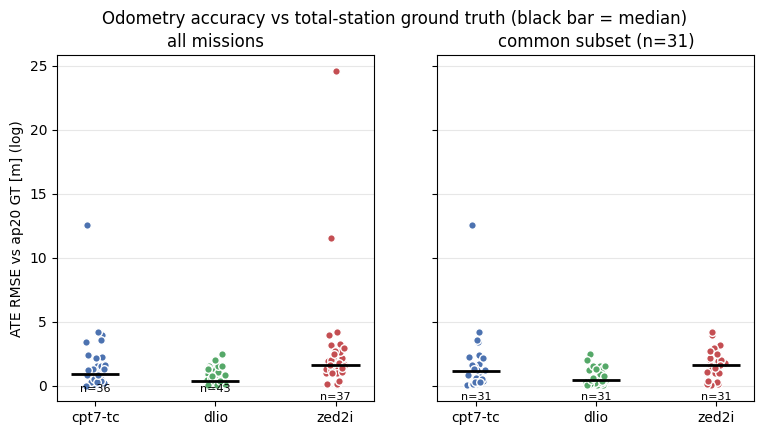

In [ ]:
np.random.seed(0)

rmse = bench.pivot(index="mission", columns="source", values="rmse")
order = [s for s in ["cpt7-tc", "dlio", "zed2i"] if s in rmse.columns]
common = rmse.dropna(
    subset=order
).index  # missions where all three sources have a result

summary = pd.concat(
    {
        "all": rmse[order].agg(["median", lambda s: s.quantile(0.95), "count"]),
        "common": rmse.loc[common, order].agg([
            "median",
            lambda s: s.quantile(0.95),
            "count",
        ]),
    },
    axis=1,
).rename(index={"<lambda>": "p95"})
print(f"common subset (all 3 sources present): {len(common)} / {len(rmse)} missions\n")
print(summary.round(3))

colors = {"cpt7-tc": "#4c72b0", "dlio": "#55a868", "zed2i": "#c44e52"}
fig, axs = plt.subplots(1, 2, figsize=(9, 4.5), sharey=True)
for ax, (label, idx) in zip(
    axs, [("all missions", rmse.index), (f"common subset (n={len(common)})", common)]
):
    for i, s in enumerate(order):
        v = rmse.loc[idx, s].dropna().values
        ax.scatter(
            i + np.random.uniform(-0.08, 0.08, len(v)),
            v,
            color=colors[s],
            s=30,
            zorder=3,
            edgecolor="white",
        )
        ax.hlines(np.median(v), i - 0.2, i + 0.2, color="k", lw=2, zorder=4)
        ax.text(
            i, ax.get_ylim()[0], f"n={len(v)}", ha="center", va="bottom", fontsize=8
        )
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order)
    ax.set_title(label)
    ax.grid(axis="y", which="both", alpha=0.3)
# axs[0].set_yscale("log")
axs[0].set_ylabel("ATE RMSE vs ap20 GT [m]")
fig.suptitle("Odometry accuracy vs total-station ground truth (black bar = median)")
# plt.tight_layout()
fig.savefig("odometry_vs_ap20_ate.pdf")
plt.show()

In [ ]:
# Per-mission ATE RMSE with GT temporal coverage (% of mission window) and spatial extent (bbox diag).
# n = matched ap20 samples per source: each source is scored over its own GT overlap, so n differs.
# Bold = best (lowest RMSE) source for that mission.
rmse_t = bench.pivot(index="mission", columns="source", values="rmse")[order]
n_t = bench.pivot(index="mission", columns="source", values="n")[order].add_suffix(" n")
table = rmse_t.join(n_t).join(coverage[["cover_%", "bbox_diag_m"]]).sort_values("dlio")
n_cols = [f"{s} n" for s in order]
(
    table.style
    .highlight_min(subset=order, axis=1, props="font-weight:bold")
    .format("{:.3f}", subset=order, na_rep="")
    .format("{:.0f}", subset=n_cols, na_rep="")
    .format("{:.1f}", subset=["cover_%", "bbox_diag_m"], na_rep="")
)

,cpt7-tc,dlio,zed2i,cpt7-tc n,dlio n,zed2i n,cover_%,bbox_diag_m
mission,,,,,,,,
SPX-3,0.017,0.027,,2229,2229,,60.4,15.6
LEICA-2,0.504,0.034,,3423,3423,,75.4,40.0
ETH-3,0.038,0.040,3.219,545,545,545,21.1,21.8
ARC-6,,0.043,11.535,,3173,3173,89.4,17.1
ICE-1,3.972,0.046,,3958,3958,,78.1,20.5
ARC-5,0.604,0.054,0.034,2987,2987,155,73.1,24.7
HAUS-1,,0.057,1.205,,3951,3951,87.5,37.0
SBB-2,0.317,0.081,1.078,4082,4080,3417,90.2,61.2
ARC-4,0.690,0.087,0.300,1514,1514,883,59.3,18.1


### Results

- ZED2i odom unusable
- On common subset (all three sources present): dlio 0.47 m vs cpt7-tc 1.14 m vs zed2i 1.61 m.
- p95 ATE RMSE: **dlio 1.57 m** vs cpt7-tc 4.03 m vs zed2i 5.68 m; dlio is also far more consistent, with no catastrophic outliers, whereas cpt7-tc reaches >12 m (HÖB-1) and ~4 m (ICE-1)